# Initial Analysis

In [1]:
import pandas as pd
import os

In [3]:
os.chdir('..')
os.getcwd()

'c:\\Users\\ebowen\\Box\\Wu Lab\\Project - statin\\8. RNA-seq\\Elizabeth\\LW15 analysis\\LW15-Functional-Screening'

In [4]:
expected_counts = pd.read_csv('Graeber/GSE240057_PARCB_timecourse_expected_counts_all_batches.txt', sep='\t')
norm_counts = pd.read_csv('Graeber/GSE240057_PARCB_timecourse_log2_upper_norm_counts_all_batches.txt', sep='\t')

norm_counts

,gene,P1-TP1,P1-TP2,P1-TP3,P1-TP4,P1-TP5,P2-TP1,P2-TP2,P2-TP3,P2-TP4,...,P9-TP1,P9-TP2,P9-TP3,P9-TP4,P9-TP5,P10-TP1,P10-TP2,P10-TP3,P10-TP4,P10-TP5
0,5_8S_rRNA,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,5_8S_rRNA.2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,5S_rRNA,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,5S_rRNA.10,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.106214,0.000000,0.000000,0.000000,0.000000,0.232906,0.000000,0.000000,0.000000
4,5S_rRNA.11,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.106214,0.000000,0.000000,0.000000,0.000000,0.232906,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60443,ZYG11B,9.900484,10.405564,9.510299,9.516295,9.753907,9.741255,9.944033,9.719683,10.201404,...,11.059999,11.263870,10.993410,11.112287,11.161109,11.000757,11.829798,10.365257,9.128969,11.302044
60444,ZYX,13.221719,12.750075,12.710939,11.957797,11.895792,13.301668,12.904858,12.007877,11.454684,...,13.223963,13.077306,12.043960,11.863807,11.471668,13.329028,13.324183,13.391347,11.370569,11.851857
60445,ZYXP1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
60446,ZZEF1,11.666913,11.255013,11.773243,11.951420,11.873730,11.761521,11.167974,11.596049,11.397000,...,12.441159,12.063330,11.937488,11.961771,12.321317,12.395578,12.590291,11.940696,11.871098,11.392457


In [6]:
genes = pd.read_html('variance_genes.html')[0]['Gene Name']
# genes
# create a dict with the corresponding rows for each of the 320 genes
norm_genes = norm_counts['gene'] 
missing_genes = []
i = 1
for gene in genes:
    # find every instance of norm_counts['gene'] that contains the gene name substring
    matches_bool = norm_genes.str.contains(gene, case=False)
    # matches_list = norm_genes[matches_bool]
    if not matches_bool.any(): # if it's empty
        missing_genes.append(gene)
        print(i)
        i += 1

# genes_dict
    
missing_genes = pd.Series(missing_genes)
# missing_genes.to_csv('missing_genes.csv')

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18


# Heat Map

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
norm_counts.set_index('gene', inplace=True)
norm_counts

,P1-TP1,P1-TP2,P1-TP3,P1-TP4,P1-TP5,P2-TP1,P2-TP2,P2-TP3,P2-TP4,P2-TP5,...,P9-TP1,P9-TP2,P9-TP3,P9-TP4,P9-TP5,P10-TP1,P10-TP2,P10-TP3,P10-TP4,P10-TP5
gene,,,,,,,,,,,,,,,,,,,,,
5_8S_rRNA,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5_8S_rRNA.2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5S_rRNA,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5S_rRNA.10,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.106214,0.000000,0.000000,0.000000,0.000000,0.232906,0.000000,0.000000,0.000000
5S_rRNA.11,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.106214,0.000000,0.000000,0.000000,0.000000,0.232906,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZYG11B,9.900484,10.405564,9.510299,9.516295,9.753907,9.741255,9.944033,9.719683,10.201404,10.521745,...,11.059999,11.263870,10.993410,11.112287,11.161109,11.000757,11.829798,10.365257,9.128969,11.302044
ZYX,13.221719,12.750075,12.710939,11.957797,11.895792,13.301668,12.904858,12.007877,11.454684,11.319360,...,13.223963,13.077306,12.043960,11.863807,11.471668,13.329028,13.324183,13.391347,11.370569,11.851857
ZYXP1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [9]:
gene = 'MME'
# Extract data for the current gene
gene_data = norm_counts.loc[gene]
print(gene_data)
# Reset the index to make it a column in the DataFrame
gene_df = gene_data.reset_index()
gene_df
# Split the 'index' column into 'PatientSeries' and 'TimePoint'
gene_df[['PatientSeries', 'TimePoint']] = gene_df['index'].str.split('-', expand=True)
gene_df
# Drop the original 'index' column
gene_df = gene_df.drop(columns=['index'])

# Pivot the DataFrame to get 'PatientSeries' as rows and 'TimePoint' as columns
pivot_df = gene_df.pivot(index='PatientSeries', columns='TimePoint', values='MME')
# Define the order of index names explicitly
new_order = ['P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P9', 'P10']

# Reorder rows based on the defined order
pivot_df = pivot_df.reindex(new_order)

pivot_df
# rename the columns
columns = ['Basal Cells', 'Organoids', 'Early Tumors', 'Transitional Tumors', 'Endpoint Tumors (ASCL2+)', 'Endpoint Tumors (ASCL1+)']
pivot_df.columns = columns
pivot_df

P1-TP1      8.749400
P1-TP2      9.775894
P1-TP3      9.454928
P1-TP4      4.282973
P1-TP5      1.582074
P2-TP1      6.877423
P2-TP2      9.984542
P2-TP3     10.034771
P2-TP4      8.612815
P2-TP5      7.489976
P2-TP6      9.497064
P3-TP1      8.381176
P3-TP2      9.463786
P3-TP3     10.264776
P3-TP4      8.579251
P3-TP5     11.002511
P4-TP1     10.671253
P4-TP2     10.105733
P4-TP3      9.725165
P4-TP4      9.811088
P4-TP5      8.077779
P5-TP1      7.729322
P5-TP2      9.101648
P5-TP3      8.707894
P5-TP4      7.630850
P5-TP5      9.284862
P5-TP6      8.207689
P6-TP1      9.240307
P6-TP2     12.462628
P6-TP3      7.771812
P6-TP4      8.789139
P6-TP5      8.227076
P6-TP6      7.440462
P7-TP1     10.615593
P7-TP2     11.660659
P7-TP3      9.298164
P7-TP4      5.884613
P7-TP5      4.912640
P7-TP6      3.324609
P8-TP1      9.621871
P8-TP2     11.786910
P8-TP3     10.923606
P8-TP4     10.272717
P8-TP5     10.313046
P8-TP6      8.924120
P9-TP1      9.790242
P9-TP2     11.923580
P9-TP3      9

,Basal Cells,Organoids,Early Tumors,Transitional Tumors,Endpoint Tumors (ASCL2+),Endpoint Tumors (ASCL1+)
PatientSeries,,,,,,
P1,8.749400,9.775894,9.454928,4.282973,1.582074,NaN
P2,6.877423,9.984542,10.034771,8.612815,7.489976,9.497064
P3,8.381176,9.463786,10.264776,8.579251,11.002511,NaN
P4,10.671253,10.105733,9.725165,9.811088,8.077779,NaN
P5,7.729322,9.101648,8.707894,7.630850,9.284862,8.207689
P6,9.240307,12.462628,7.771812,8.789139,8.227076,7.440462
P7,10.615593,11.660659,9.298164,5.884613,4.912640,3.324609
P8,9.621871,11.786910,10.923606,10.272717,10.313046,8.924120
P9,9.790242,11.923580,9.158974,10.193513,10.206350,NaN


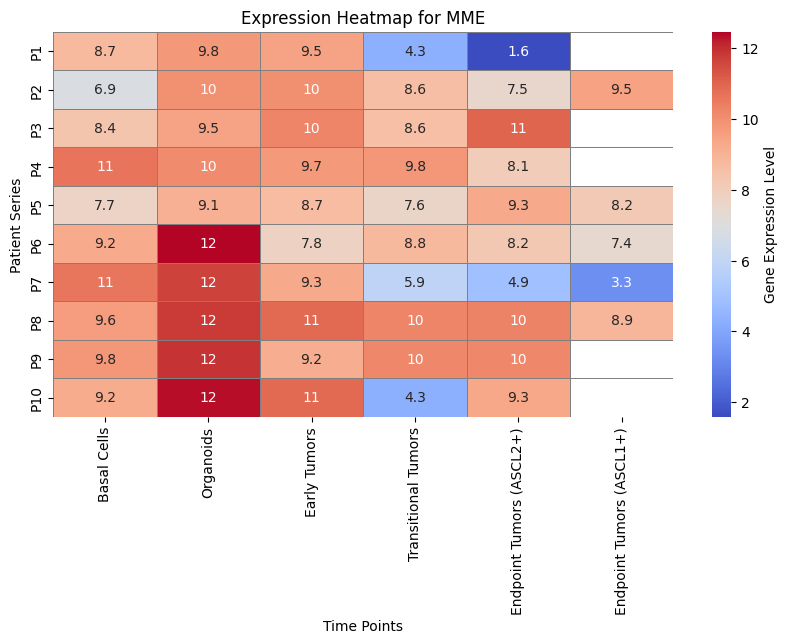

In [10]:
# Replace NaN values with a number that indicates missing data (e.g., -1)
gene_df = pivot_df.fillna(-1)

# Plot the heatmap
plt.figure(figsize=(10, 5))  # Adjust the size as needed
ax = sns.heatmap(gene_df, annot=True, cmap='coolwarm', cbar=True, linewidths=.5, linecolor='grey',
            mask=gene_df == -1)  # Masking the missing values

# Add the colorbar with a title
colorbar = ax.collections[0].colorbar
colorbar.set_label('Gene Expression Level')


# Customize the plot as needed
plt.title(f'Expression Heatmap for {gene}')
plt.xlabel('Time Points')
plt.ylabel('Patient Series')
plt.show()


# Scatter plot

/var/folders/5h/nw2bw54501q8yzhtr7fv7qnc0000gq/T/ipykernel_59460/3158172998.py:48: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.
  plt.colorbar(sm, label='Gene Expression Level', location='left')


(<Figure size 500x800 with 2 Axes>,
 <Axes: title={'center': 'ASCL1 Expression Levels across Tumor Categories'}, xlabel='Tumor Category', ylabel='ExpressionLevel'>)

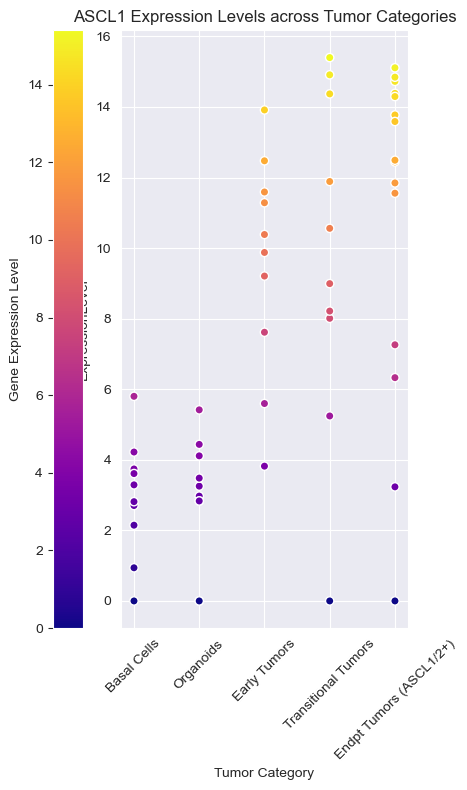

In [92]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_gene_expression(gene, norm_counts):
    gene_data = norm_counts.loc[gene].reset_index()
    gene_data[['PatientSeries', 'TimePoint']] = gene_data['index'].str.split('-', expand=True)
    gene_data = gene_data.drop(columns=['index'])
    pivot_df = gene_data.pivot(index='PatientSeries', columns='TimePoint', values=gene)
    new_order = ['P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P9', 'P10']
    pivot_df = pivot_df.reindex(new_order)

    # Rename the columns to more descriptive names
    columns = ['Basal Cells', 'Organoids', 'Early Tumors', 'Transitional Tumors', 'Endpoint Tumors (ASCL2+)', 'Endpoint Tumors (ASCL1+)']
    pivot_df.columns = columns

    # Melt the DataFrame for plotting
    melted_df = pivot_df.reset_index().melt(id_vars='PatientSeries', var_name='TumorCategory', value_name='ExpressionLevel')

    # Prepare data for 'Endpoint Tumors'
    ascl2_data = melted_df[melted_df['TumorCategory'] == 'Endpoint Tumors (ASCL2+)'].copy()
    ascl1_data = melted_df[melted_df['TumorCategory'] == 'Endpoint Tumors (ASCL1+)'].copy()

    # Change 'TumorCategory' for these dataframes to 'Endpoint Tumors'
    ascl2_data['TumorCategory'] = 'Endpt Tumors (ASCL1/2+)'
    ascl1_data['TumorCategory'] = 'Endpt Tumors (ASCL1/2+)'

    # Append these modified dataframes back to the original melted dataframe
    # First, filter out the original ASCL2+ and ASCL1+ rows
    melted_df = melted_df[~melted_df['TumorCategory'].isin(['Endpoint Tumors (ASCL2+)', 'Endpoint Tumors (ASCL1+)'])]

    # Then, append the modified ASCL2+ and ASCL1+ data
    melted_df = pd.concat([melted_df, ascl2_data, ascl1_data], ignore_index=True)

    # Plotting
    plt.figure(figsize=(5, 8))
    ax = sns.scatterplot(data=melted_df, x='TumorCategory', y='ExpressionLevel',
                         hue='ExpressionLevel', palette='plasma', linewidth=1, legend=False)
    plt.xticks(rotation=45)
    plt.title(f'{gene} Expression Levels across Tumor Categories')
    plt.xlabel('Tumor Category')
    plt.tight_layout()
    
    # Adding a colorbar
    norm = plt.Normalize(melted_df['ExpressionLevel'].min(), melted_df['ExpressionLevel'].max())
    sm = plt.cm.ScalarMappable(cmap="plasma", norm=norm)
    sm.set_array([])
    plt.colorbar(sm, label='Gene Expression Level', location='left')
    
    plt.savefig(f'plot_data/scatter_plots/{gene}_expression_plot.png', bbox_inches='tight')

    return plt.gcf(), ax

# Ensure 'norm_counts' is defined and contains the expected data structure before calling this function.
plot_gene_expression('ASCL1', norm_counts)


**Function to plot heat map**

(<Figure size 1000x500 with 2 Axes>,
 <Axes: title={'center': 'Expression Heatmap for ASCL1'}, xlabel='Time Points', ylabel='Patient Series'>)

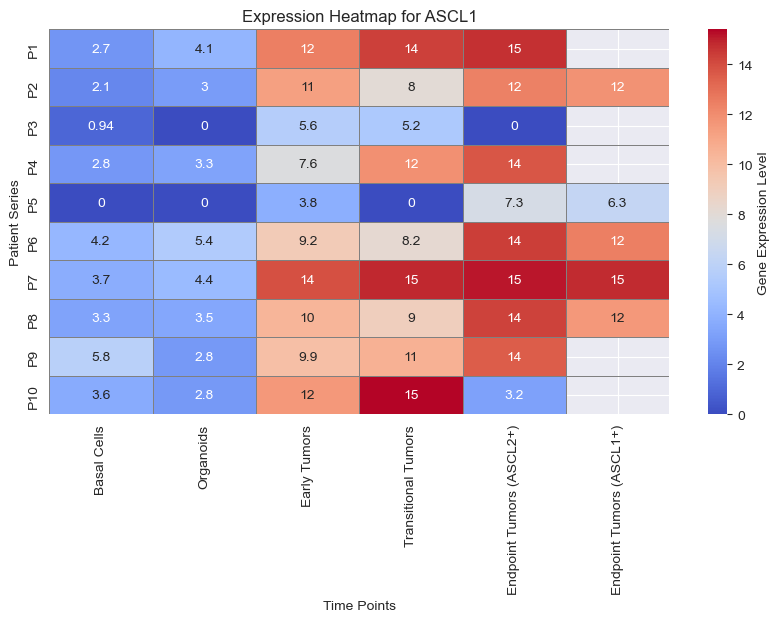

In [102]:

def plot_heat_map(gene, norm_counts):
    """
    Parameters:
    - gene: str, the name of the gene to extract data for
    - norm_counts: DataFrame, a DataFrame with gene names as the index and 
      'PatientSeries-TimePoint' as columns

    Returns:
    - A matplotlib figure and axis object of the heat map/
    """
    # Extract data for the current gene
    gene_data = norm_counts.loc[gene].reset_index()

    # Split the 'index' column into 'PatientSeries' and 'TimePoint'
    gene_data[['PatientSeries', 'TimePoint']] = gene_data['index'].str.split('-', expand=True)

    # Drop the original 'index' column
    gene_data = gene_data.drop(columns=['index'])

    # Pivot the DataFrame to get 'PatientSeries' as rows and 'TimePoint' as columns
    pivot_df = gene_data.pivot(index='PatientSeries', columns='TimePoint', values=gene)

    # Define the order of index names explicitly and reorder rows
    new_order = ['P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P9', 'P10']
    pivot_df = pivot_df.reindex(new_order)

    # Rename the columns to more descriptive names
    columns = ['Basal Cells', 'Organoids', 'Early Tumors', 'Transitional Tumors',
               'Endpoint Tumors (ASCL2+)', 'Endpoint Tumors (ASCL1+)']
    pivot_df.columns = columns
    
    pivot_df.to_csv(f'plot_data/{gene}_pivot_data.csv')
    # Replace NaN values with a number that indicates missing data (e.g., -1)
    gene_df = pivot_df.fillna(-1)

    # Plotting
    plt.figure(figsize=(10, 5))  # Adjust the size as needed
    ax = sns.heatmap(gene_df, annot=True, cmap='coolwarm', cbar=True, linewidths=.5, linecolor='grey',
                     mask=gene_df == -1)  # Masking the missing values
    
    # Add the colorbar with a title
    colorbar = ax.collections[0].colorbar
    colorbar.set_label('Gene Expression Level')

    # Customize and save the plot
    plt.title(f'Expression Heatmap for {gene}')
    plt.xlabel('Time Points')
    plt.ylabel('Patient Series')
    plt.savefig(f'heat_maps/{gene}_heat_map.png', bbox_inches='tight')

    return plt.gcf(), ax


plot_heat_map('ASCL1', norm_counts)


# Testing
Try on ASCL1, ASCL2 (hits) & VHL (non-hit)

ValueError: Unknown format code 'g' for object of type 'str'

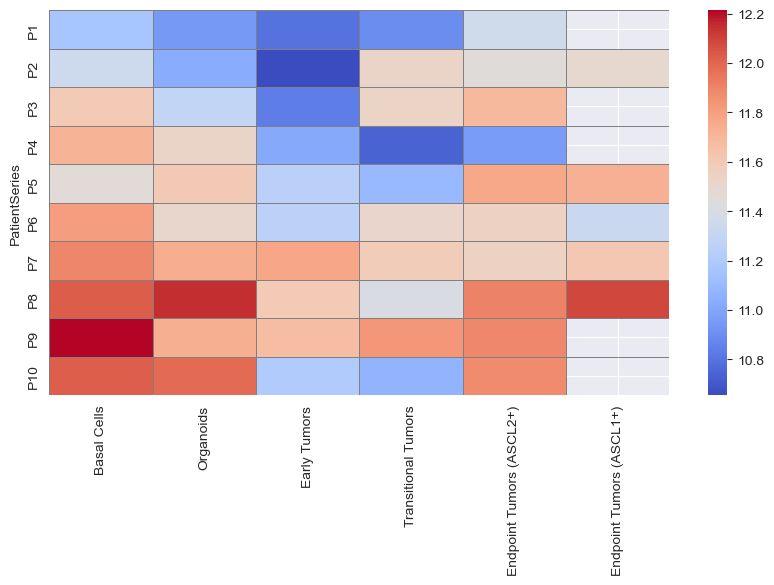

In [106]:
def plot_heat_map(gene, norm_counts):
    """
    Adjusted the code to format numeric values to strings with desired precision for heatmap annotations.
    """
    # Extract data for the current gene
    gene_data = norm_counts.loc[gene].reset_index()

    # Split the 'index' column into 'PatientSeries' and 'TimePoint'
    gene_data[['PatientSeries', 'TimePoint']] = gene_data['index'].str.split('-', expand=True)

    # Drop the original 'index' column
    gene_data = gene_data.drop(columns=['index'])

    # Pivot the DataFrame to get 'PatientSeries' as rows and 'TimePoint' as columns
    pivot_df = gene_data.pivot(index='PatientSeries', columns='TimePoint', values=gene)

    # Define the order of index names explicitly and reorder rows
    new_order = ['P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P9', 'P10']
    pivot_df = pivot_df.reindex(new_order)

    # Rename the columns to more descriptive names
    columns = ['Basal Cells', 'Organoids', 'Early Tumors', 'Transitional Tumors', 'Endpoint Tumors (ASCL2+)', 'Endpoint Tumors (ASCL1+)']
    pivot_df.columns = columns

    # Replace NaN values with a number that indicates missing data (e.g., -1)
    gene_df = pivot_df.fillna(-1)

    # Apply formatting to numeric values before converting to strings, ensuring all values maintain desired precision
    formatted_gene_df = gene_df.applymap(lambda x: f'{x:.4f}' if isinstance(x, (int, float)) and x != -1 else x)

    # Plotting
    plt.figure(figsize=(10, 5))
    ax = sns.heatmap(gene_df, annot=formatted_gene_df, cmap='coolwarm', cbar=True, linewidths=.5, linecolor='grey',
                     mask=gene_df == -1)  # Masking -1 values to indicate missing data

    # Add the colorbar with a title
    colorbar = ax.collections[0].colorbar
    colorbar.set_label('Gene Expression Level')

    # Customize and save the plot
    plt.title(f'Expression Heatmap for {gene}')
    plt.xlabel('Time Points')
    plt.ylabel('Patient Series')
    plt.savefig(f'heat_maps/{gene}_heat_map.png', bbox_inches='tight')

    return plt.gcf(), ax

plot_heat_map('VHL', norm_counts)


# Bar Graph

In [11]:
def plot_bar_graph(gene, norm_counts):
    """
    Plots a bar graph with error bars and individual points for the specified gene's
    expression levels across different time points.

    Parameters:
    - gene: str, the name of the gene to plot
    - norm_counts: DataFrame, a DataFrame with gene names as the index and
      'PatientSeries-TimePoint' as columns
    """
    # Extract data for the specified gene
    gene_data = norm_counts.loc[gene].reset_index()

    # Split the 'index' column into 'PatientSeries' and 'TimePoint'
    gene_data[['PatientSeries', 'TimePoint']] = gene_data['index'].str.split('-', expand=True)

    # Drop the original 'index' column
    gene_data = gene_data.drop(columns=['index'])

    # Pivot the DataFrame to get 'PatientSeries' as rows and 'TimePoint' as columns
    pivot_df = gene_data.pivot(index='PatientSeries', columns='TimePoint', values=gene)

    # Calculate mean and standard deviation for each 'TimePoint'
    means = pivot_df.mean()
    stds = pivot_df.std()

    columns = ['Basal Cells', 'Organoids', 'Early Tumors', 'Transitional Tumors', 'Endpoint Tumors (ASCL2+)', 'Endpoint Tumors (ASCL1+)']
    pivot_df.columns = columns
    
    # Define the color map
    colors = plt.cm.cool(np.linspace(0,1,len(means)))

    # Creating the bar plot
    fig, ax = plt.subplots()
    time_points = np.arange(len(means))  # X locations for the groups
    bar_width = 0.35  # Width of the bars

    # Plot bars
    bars = ax.bar(time_points, means, bar_width, yerr=stds, align='center', alpha=0.7, ecolor='black', capsize=5, color=colors)

    # Plot individual points
    for i, time_point in enumerate(pivot_df.columns):
        y = pivot_df[time_point]
        x = np.random.normal(i, 0.04, size=len(y))  # Add some jitter to the X-axis
        ax.scatter(x, y, alpha=0.8, color=colors[i])

    ax.set_ylabel('Gene Expression Level')
    ax.set_ylim(bottom=0)  # Minimum limit is set to 0
    ax.set_title(f'Expression Levels of {gene} Across Time Points')
    ax.set_xticks(time_points)
    ax.set_xticklabels(pivot_df.columns, rotation=45)
    ax.legend()

    plt.savefig(f'{gene}_bar_graph.png', bbox_inches='tight')

In [12]:
norm_counts.set_index('gene', inplace = True)

norm_counts

KeyError: "None of ['gene'] are in the columns"

In [13]:
os.chdir('Graeber')

In [15]:
genes

0         Mme
1       Greb1
2       Ifi44
3     Hspa12a
4      Rnf130
       ...   
70    Gtpbp10
71       Snca
72       Islr
73     Slc7a3
74     Thsd7a
Name: Gene Name, Length: 75, dtype: object

In [ ]:
# turn every gene in genes uppercase
genes = genes.str.upper()

# create plotds for every gene in genes
for gene in genes:
    try:
        plot_bar_graph(gene, norm_counts)
        plt.savefig(f'bar_graphs/{gene}_bar_graph.png', bbox_inches='tight')
    except Exception as e:
        print(f"Error plotting {gene}: {e}")

C:\Users\ebowen\AppData\Local\Temp\ipykernel_26560\14722265.py:52: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
C:\Users\ebowen\AppData\Local\Temp\ipykernel_26560\14722265.py:52: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
C:\Users\ebowen\AppData\Local\Temp\ipykernel_26560\14722265.py:52: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
C:\Users\ebowen\AppData\Local\Temp\ipykernel_26560\14722265.py:52: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legen

Error plotting XLR3A: 'XLR3A'


C:\Users\ebowen\AppData\Local\Temp\ipykernel_26560\14722265.py:52: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
C:\Users\ebowen\AppData\Local\Temp\ipykernel_26560\14722265.py:52: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()
C:\Users\ebowen\AppData\Local\Temp\ipykernel_26560\14722265.py:52: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


C:\Users\ebowen\AppData\Local\Temp\ipykernel_26560\14722265.py:52: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


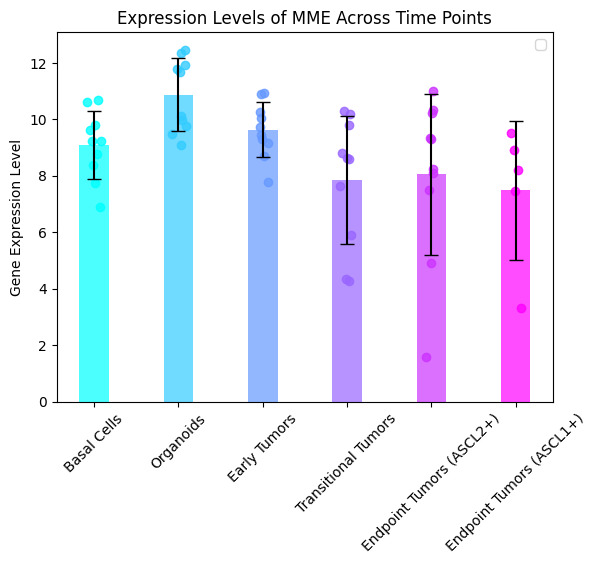

In [14]:
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
# Example usage, assuming 'norm_counts' is your DataFrame
plot_bar_graph('MME', norm_counts)
gene = 'MME'
plt.savefig(f'bar_graphs/{gene}_bar_graph.png', bbox_inches='tight')

save all the genes of interest dataframes:

In [ ]:
for gene in genes:
    if gene not in missing_genes:
        gene_data = prepare_gene_data(gene, norm_counts)
        gene_data.to_csv(f'{gene}_expression_data.csv')
    

**Notebook scratch**


In [7]:
data = pd.read_html('index.html')[0]
data

,Gene Name,Regulation in Sensitive,CRISPR cov.,cDNA cov.,Gene ID,Found in,Category,Description,Gene Plot,TCGA Survival Curve,Survival Curve p-val,pval sorting index,Expression of Higher Survival group,LW15 vs TCGA
0,4931428F04Rik,Upregulated,No coverage,No coverage,ENSMUSG00000014837,PCA,None,not well characterized,NaN,NaN,NaN,500,NaN,NaN
1,Caskin1,Upregulated,4,0,ENSMUSG00000033597,PCA,None,"Synaptic function, neural development, signal ...",NaN,NaN,1.230000e-01,174,NaN,NaN
2,Scarf2,Upregulated,3,0,ENSMUSG00000012017,PCA,Cell Adhesion & Signaling,"Implicated in cell adhesion, signaling pathway...",NaN,NaN,7.470000e-03,91,Low,same
3,Vps4a,Upregulated,3,1,ENSMUSG00000031913,PCA,Autophagy & DNA Repair,"Vesicular trafficking, endosomal sorting, auto...",NaN,NaN,1.548000e-01,184,NaN,NaN
4,Card10,Upregulated,2,0,ENSMUSG00000033170,PCA,Cell Adhesion & Signaling,"CARD-containing, involved in NF-ÎºB activation...",NaN,NaN,5.207000e-01,236,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
315,Asah1,Downregulated,3,1,ENSMUSG00000031591,GSEA down,Metabolism,"Involved in sphingolipid metabolism, alteratio...",NaN,NaN,1.020000e-05,20,High,same
316,Myo6,Downregulated,3,1,ENSMUSG00000033577,GSEA down,Membrane Proteins & Endocytosis,Involved in endocytosis and intracellular traf...,NaN,NaN,3.200000e-08,4,High,same
317,Ranbp2,Downregulated,3,0,ENSMUSG00000003226,GSEA down,None,"Involved in nucleocytoplasmic transport, also ...",NaN,NaN,5.890000e-04,52,High,same
318,Sord,Downregulated,5,1,ENSMUSG00000027227,GSEA down,Metabolism,Involved in the polyol pathway of glucose meta...,NaN,NaN,1.130000e-02,101,High,same


In [8]:
upregulated = []
downregulated = []
for index, row in data.iterrows():
    gene = row['Gene Name']
    regulation = row['Regulation in Sensitive']
    if regulation == 'Upregulated':
        upregulated.append(gene)
    else:
        downregulated.append(gene)

In [10]:
upregulated = pd.Series(upregulated)
downregulated = pd.Series(downregulated)
upregulated.to_csv('Upregulated_genes.csv')
downregulated.to_csv('Downregulated_genes.csv')

In [32]:
downregulated = downregulated.str.upper()
upregulated = upregulated.str.upper()

Downregulated:
1


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


2


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


3


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


... (497 outputs left out)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


279


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


280


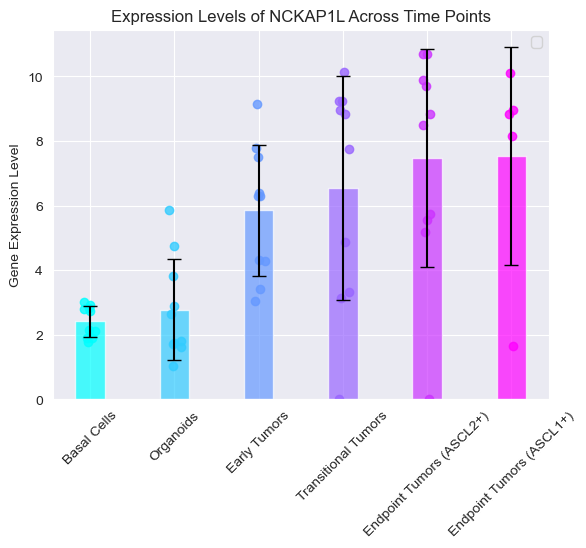

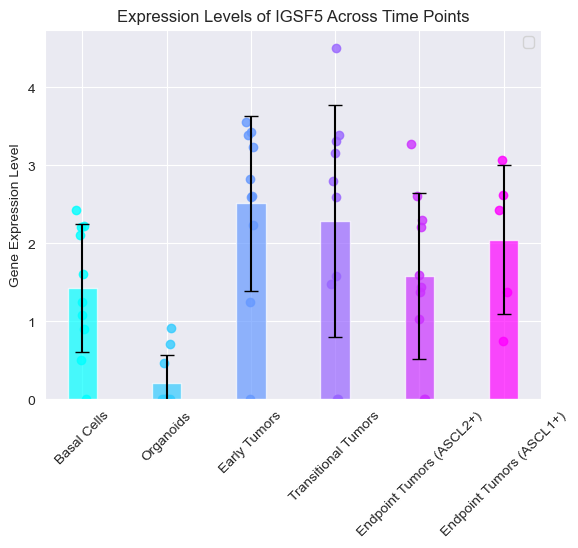

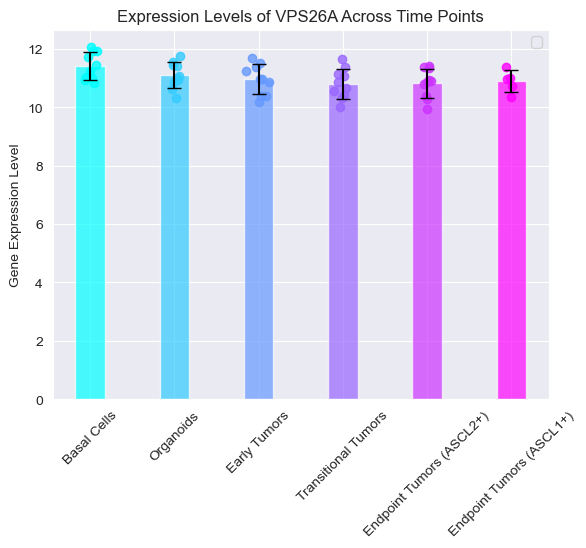

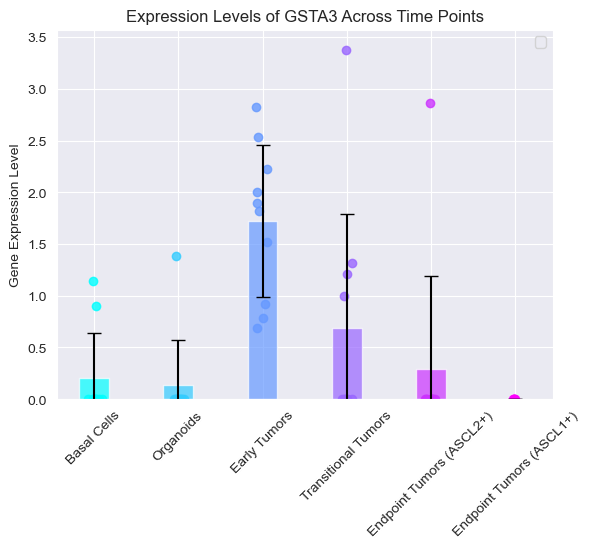

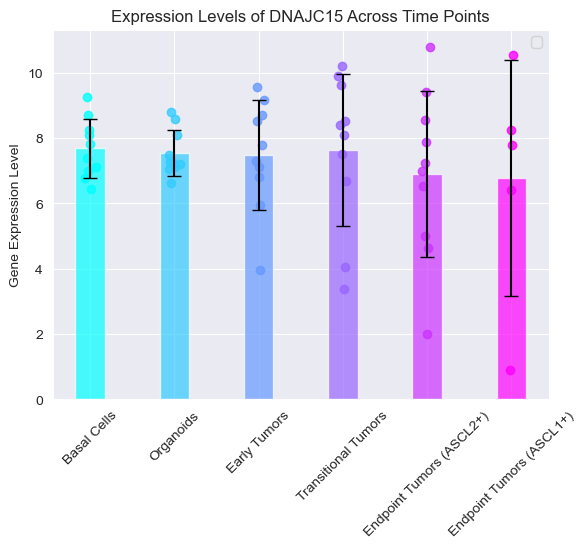

...

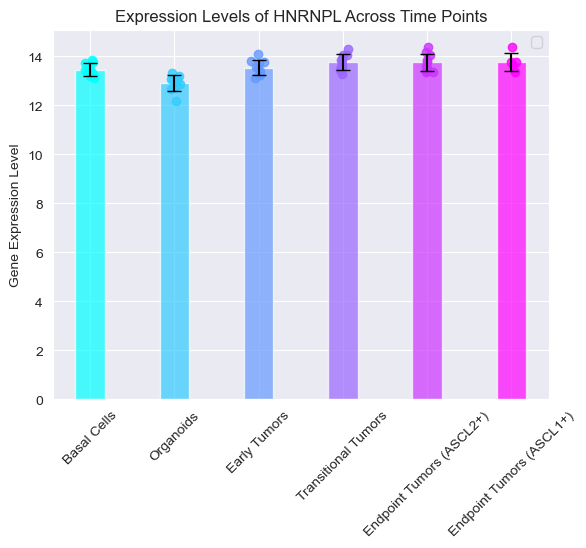

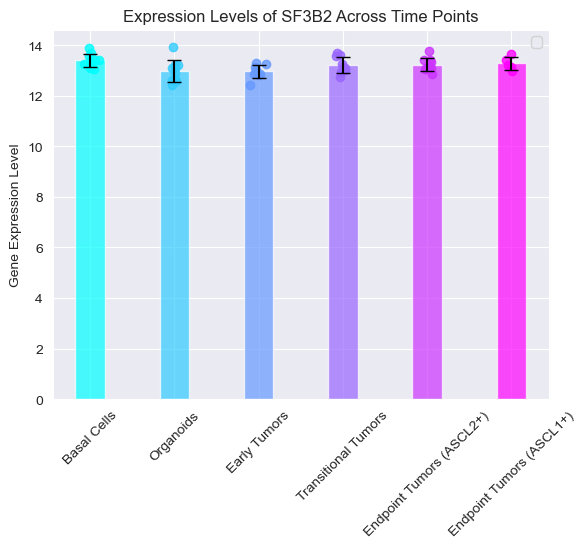

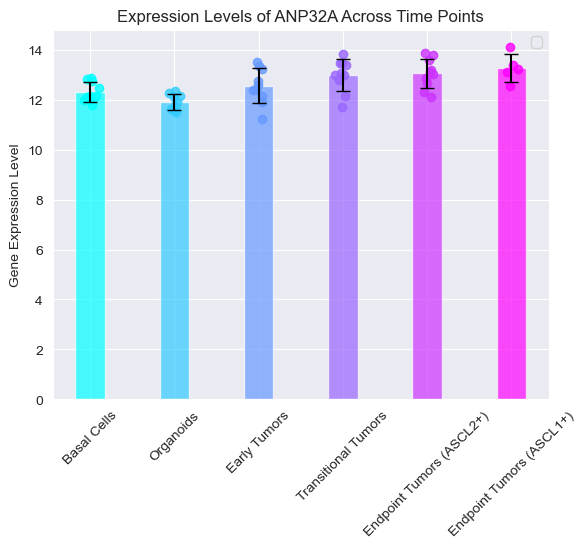

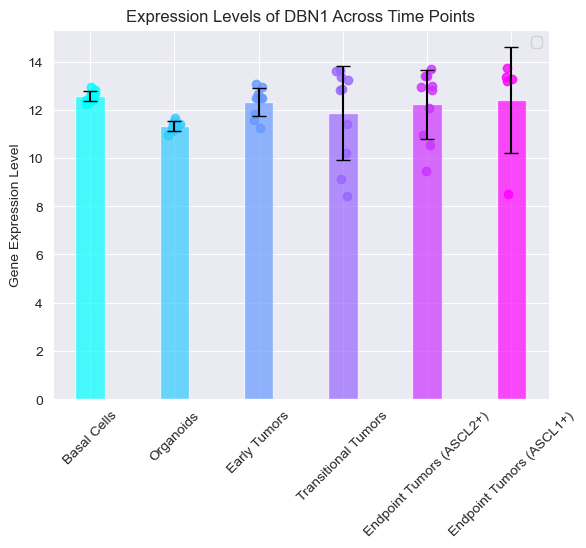

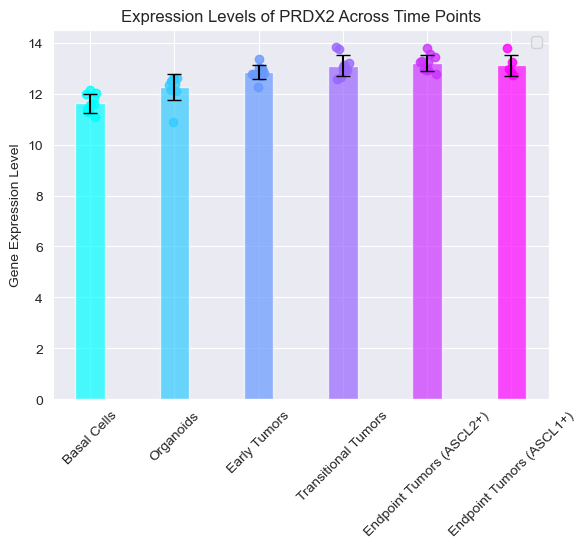

In [33]:
# os.chdir('bar_graphs/downregulated')
i = 1
print('Downregulated:')
for gene in downregulated:
    print(i)
    if gene in norm_counts.index:
        plot_bar_graph(gene, norm_counts)
    else:
        print(f'Gene {gene} not found')
    i +=1

os.chdir('../upregulated')
j = 1
for gene in upregulated:
    print(j)
    if gene in norm_counts.index:
        plot_bar_graph(gene, norm_counts)
    else:
        print(f'Gene {gene} not found')
    j +=1



In [12]:
os.getcwd()

'/Users/elizabeth 1/Library/CloudStorage/Box-Box/Wu Lab/Project - statin/8. RNA-seq/Elizabeth/LW15 analysis/LW15-Functional-Screening'